In [ ]:
from google.colab import drive
drive.mount('/content/drive/')

Mounted at /content/drive/


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

In [ ]:
dt = pd.read_csv("/content/drive/MyDrive/dsf_project/Purchase_Logistic.csv")

In [ ]:
dt.columns

Index(['User ID', 'Gender', 'Age', 'EstimatedSalary', 'Purchased'], dtype='object')

In [ ]:
dt.shape

(400, 5)

In [ ]:
dt.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   User ID          400 non-null    int64 
 1   Gender           400 non-null    object
 2   Age              400 non-null    int64 
 3   EstimatedSalary  400 non-null    int64 
 4   Purchased        400 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 15.8+ KB


In [ ]:
scaler = StandardScaler()
X_train, X_test, y_train, y_test = train_test_split(dt[['Age', 'Gender', 'EstimatedSalary']], dt[['Purchased']], random_state=42, test_size=0.2)

scalable_col = ['Age', 'EstimatedSalary']

X_train[scalable_col] = scaler.fit_transform(X_train[scalable_col])
X_test[scalable_col] = scaler.transform(X_test[scalable_col])

X_train['Gender'] = [1 if gender == "Male" else 0 for gender in X_train['Gender']]
X_test['Gender'] = [1 if gender == "Male" else 0 for gender in X_test['Gender']]

In [ ]:
model = GaussianNB()
model.fit(X_train, y_train)

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:1408: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


GaussianNB()

In [ ]:
pred = model.predict(X_test)

In [ ]:
cm = confusion_matrix(y_test, pred)
cm

array([[50,  2],
       [ 3, 25]])

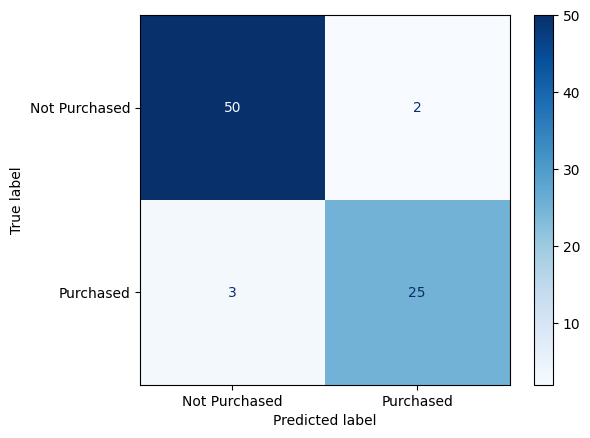

In [ ]:
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Not Purchased', 'Purchased'])
disp.plot(cmap='Blues')
plt.show()